# Rectified flow in a compliant channel via the reciprocal theorem

This notebook computes the cycle-averaged (rectified) flow produced by elastoinertial rectification of an oscillatory flow in a two-dimensional channel bounded by a confined elastic layer [RPC26], the channel counterpart of the tube problem of [ZR24]. Instead of solving a boundary-value problem (BVP) for the mean velocity at every axial position, as in [RPC26], we use a reciprocal theorem (RT) in the spirit of [PBC26], with steady Poiseuille flow as the auxiliary problem. The RT gives the mean flow rate under pressure control, or the mean pressure drop under flow-rate control, as a single quadrature.

We check the RT result against the direct BVP solution, against the small-$\mathrm{Wo}$ limit of [RPC26], and against Fig. 3(b) of [RPC26].

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

## Notation

We follow [RPC26], with one exception: their wall-shear coefficient $\mathfrak{f}_1$ is written here as $\mathfrak{f}_\mathrm{w}$, as in the channel streaming notebook, where $\mathfrak{f}_1$ denotes a different coefficient of [PWC23].

| Symbol | Meaning |
| --- | --- |
| $\beta$ | compliance number (perturbation parameter) |
| $\mathrm{Wo}$ | Womersley number |
| $\gamma$ | elastoviscous number |
| $\theta$, $\vartheta$ | parameters of the combined foundation model of [CV20] ($\theta = \vartheta = 0$ is a Winkler foundation) |
| $\mathfrak{f}_0(\mathrm{Wo})$ | flow-rate coefficient, $Q_{0,a} = \mathfrak{f}_0 \cdot (-dP_{0,a}/dZ)$ |
| $\mathfrak{f}_\mathrm{w}(\mathrm{Wo})$ | wall-shear coefficient, $\partial V_{Z,0,a}/\partial Y\vert _{Y=1} = \mathfrak{f}_\mathrm{w} \cdot (-dP_{0,a}/dZ)$ |
| $P_0$, $P_1$ | $\mathrm{O}(1)$ and $\mathrm{O}(\beta)$ pressure |
| $\hat{V}_Z$, $\hat{P}$ | auxiliary (Poiseuille) flow |

The cycle average is $\langle\,\cdot\,\rangle := \frac{1}{2\pi}\int_0^{2\pi} (\,\cdot\,) \, dT$. Complex amplitudes are used with the real part understood, e.g., $P_0 = P_{0,a}(Z)e^{iT}$. For complex amplitudes $A$ and $B$, $\langle \mathrm{Re}[A e^{iT}]\,\mathrm{Re}[B e^{iT}] \rangle = \tfrac{1}{2}\mathrm{Re}[A^* B]$, where $^*$ denotes the complex conjugate.

# Preliminaries

In [1]:
# sympy setup
import sympy as sp
sp.init_printing()

# plotting customizations
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
size=16
params = {'legend.fontsize': 'large',
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25,
          'font.family': 'serif',
          'mathtext.fontset': 'cm'}
plt.rcParams.update(params)
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

%matplotlib inline

# numerics
import numpy as np
from scipy.integrate import solve_bvp, simpson

Unless stated otherwise, we use the reference parameters below. The values of $\theta$ and $\vartheta$ are those of [RPC26, Figs. 2 and 3].

In [2]:
Wo_ref = 2.0
gamma_ref = 0.75
theta_ref = 0.0028
vartheta_ref = 0.0051

# Primary flow

The leading-order pressure amplitude is [RPC26]
$$
    P_{0,a}(Z) = \frac{\sinh\big(\kappa(1-Z)\big)}{\sinh \kappa}
$$
under pressure control ($P_{0,a}(0) = 1$, $P_{0,a}(1) = 0$), or
$$
    P_{0,a}(Z) = \frac{\sinh\big(\kappa(1-Z)\big)}{\mathfrak{f}_0 \kappa \cosh \kappa}
$$
under flow-rate control ($Q_{0,a}(0) = 1$, $P_{0,a}(1) = 0$) [RPC26, Appendix B]. In both cases,
$$
\begin{aligned}
    \kappa(\mathrm{Wo},\gamma,\theta,\vartheta) &= \sqrt{\frac{i \gamma}{\mathfrak{f}_0(\mathrm{Wo}) + i \gamma \left[\theta-\vartheta \mathfrak{f}_\mathrm{w}(\mathrm{Wo}) \right]}},\\
    \mathfrak{f}_0(\mathrm{Wo}) &= \frac{1}{i \mathrm{Wo}^2}\left[1 - \frac{\tan\left(i^{3/2} \mathrm{Wo}/2\right)}{i^{3/2} \mathrm{Wo}/2}\right],\\
    \mathfrak{f}_\mathrm{w}(\mathrm{Wo}) &= \frac{i^{1/2}}{\mathrm{Wo}} \tan\left(i^{3/2} \mathrm{Wo}/2\right).
\end{aligned}
$$
The wall displacement, axial velocity, and vertical velocity amplitudes are
$$
\begin{aligned}
    U_{Y,0,a}(Z) &= \frac{\mathfrak{f}_0}{i \gamma}\,\kappa^2 P_{0,a}(Z),\\
    V_{Z,0,a}(Y,Z) &= \frac{1}{i\mathrm{Wo}^2}\left[1-\frac{\cos\left(i^{3/2} (1-2Y)\mathrm{Wo}/2\right)}{\cos\left(i^{3/2} \mathrm{Wo}/2 \right)}\right] \left( -\frac{d P_{0,a}}{d Z} \right),\\
    V_{Y,0,a}(Y,Z) &= -\int_0^Y \frac{\partial V_{Z,0,a}}{\partial Z}\,dY'.
\end{aligned}
$$

In [3]:
I3half = sp.I**sp.Rational(3, 2)
kappa, f0, fw = sp.symbols('kappa f0 f_w')
Wo, gamma = sp.symbols('Wo gamma', positive=True)
Y, Z = sp.symbols('Y Z', positive=True)

# leading-order pressure amplitude under pressure and flow-rate control
P0a_pressure = sp.sinh(kappa*(1 - Z))/sp.sinh(kappa)
P0a_flow = sp.sinh(kappa*(1 - Z))/(f0*kappa*sp.cosh(kappa))

For each type of control, we build the two cycle-averaged quantities that drive the mean flow at $\mathrm{O}(\beta)$: the effective slip velocity at the undeformed wall,
$$
  V_\mathrm{slip}(Z) := -\left.\left\langle U_{Y,0} \frac{\partial V_{Z,0}}{\partial Y} \right\rangle\right|_{Y=1},
$$
and the advective-inertia forcing,
$$
  F(Y,Z) := \frac{\mathrm{Wo}^2}{\gamma} \left\langle V_{Y,0} \frac{\partial V_{Z,0}}{\partial Y} + V_{Z,0} \frac{\partial V_{Z,0}}{\partial Z} \right\rangle.
$$
Both are lambdified for vectorized evaluation with NumPy.

In [4]:
def half_re(a, b):
  # < Re[a e^{iT}] Re[b e^{iT}] > = Re[a^* b]/2
  return sp.re(sp.conjugate(a)*b)/2

def mean_flow_drivers(P0a):
  U0a = f0/(sp.I*gamma)*kappa**2*P0a
  Vz0a = 1/(sp.I*Wo**2)*(1 - sp.cos(I3half*(1 - 2*Y)*Wo/2)/sp.cos(I3half*Wo/2))*(-P0a.diff(Z))
  f = sp.Function('f')
  Vy0a = sp.dsolve(sp.Eq(f(Y).diff(Y) + Vz0a.diff(Z), 0), ics={f(0): 0}).rhs
  slip = -half_re(U0a, Vz0a.diff(Y).subs(Y, 1))
  forcing = Wo**2/gamma*(half_re(Vy0a, Vz0a.diff(Y)) + half_re(Vz0a, Vz0a.diff(Z)))
  args = (Y, Z, kappa, f0, fw, Wo, gamma)
  return sp.lambdify(args, slip, 'numpy'), sp.lambdify(args, forcing, 'numpy')

slip_pressure, forcing_pressure = mean_flow_drivers(P0a_pressure)
slip_flow, forcing_flow = mean_flow_drivers(P0a_flow)

In [5]:
def coefficients(Wo, gamma, theta, vartheta):
  a = 1j**(3/2)*Wo/2
  f0 = (1 - np.tan(a)/a)/(1j*Wo**2)
  fw = np.sqrt(1j)/Wo*np.tan(a)
  kappa = np.sqrt(1j*gamma/(f0 + 1j*gamma*(theta - vartheta*fw)))
  return kappa, f0, fw

# Mean (rectified) flow

At $\mathrm{O}(\beta)$, the cycle-averaged flow satisfies [RPC26]
$$
  \frac{\partial^2 \langle V_{Z,1} \rangle}{\partial Y^2} - \frac{d \langle P_1\rangle }{d Z} = F,
  \qquad
  \langle V_{Z,1} \rangle|_{Y=0} = 0,\quad \langle V_{Z,1} \rangle|_{Y=1} = V_\mathrm{slip},
$$
with $\langle Q_1 \rangle = \int_0^1 \langle V_{Z,1} \rangle\,dY$ independent of $Z$. Writing $\langle V_{Z,1} \rangle = -\tfrac{1}{2}\tfrac{d \langle P_1\rangle}{dZ} Y(1-Y) + Y V_\mathrm{slip} + \widetilde{\langle V_{Z,1}\rangle}$, the remainder solves the BVP
$$
  \frac{\partial^2 \widetilde{\langle V_{Z,1}\rangle}}{\partial Y^2} = F,
  \qquad
  \widetilde{\langle V_{Z,1}\rangle}|_{Y=0} = \widetilde{\langle V_{Z,1}\rangle}|_{Y=1} = 0,
$$
at each $Z$. Integrating over the channel, with $\langle \Delta P_1 \rangle := \langle P_1\rangle(0) - \langle P_1\rangle(1)$,
$$
  \langle Q_1 \rangle - \frac{1}{12}\langle \Delta P_1 \rangle = \underbrace{\int_0^1 \tfrac{1}{2} V_\mathrm{slip}\,dZ}_{I_1} + \underbrace{\int_0^1\!\!\int_0^1 \widetilde{\langle V_{Z,1}\rangle}\,dY\,dZ}_{I_2}.
$$
Under pressure control, $\langle \Delta P_1 \rangle = 0$ gives the rectified flow rate $\langle Q_1 \rangle = I_1 + I_2$. Under flow-rate control, $\langle Q_1 \rangle = 0$ gives the rectified pressure drop $\langle \Delta P_1 \rangle = -12(I_1 + I_2)$.

## Reciprocal theorem

Take as the auxiliary problem steady Poiseuille flow in the undeformed channel,
$$
  \frac{d^2 \hat{V}_Z}{dY^2} - \frac{d\hat{P}}{dZ} = 0, \qquad \hat{V}_Z|_{Y=0} = \hat{V}_Z|_{Y=1} = 0, \qquad \hat{P} = 1 - Z,
$$
so that $\hat{V}_Z = \tfrac{1}{2}Y(1-Y)$ and $\hat{Q} = 1/12$. Multiplying the mean-flow equation by $\hat{V}_Z$, the auxiliary equation by $\langle V_{Z,1} \rangle$, subtracting, and integrating by parts over the channel, the bulk viscous terms cancel and only boundary terms remain. This gives the RT
$$
  \langle Q_1 \rangle - \frac{1}{12}\langle \Delta P_1 \rangle
  = \int_0^1 \tfrac{1}{2} V_\mathrm{slip}\,dZ - \int_0^1\!\!\int_0^1 F\, \hat{V}_Z\,dY\,dZ,
$$
in which the slip enters through the boundary term $-\hat{V}_Z'(1) = \tfrac{1}{2}$. Comparing with the expression above, $I_2 = -\int_0^1\!\int_0^1 F \hat{V}_Z\,dY\,dZ$. For this one-dimensional mean problem, the RT reduces exactly to Green's identity for the BVP for $\widetilde{\langle V_{Z,1}\rangle}$, but it was derived independently of that BVP, so agreement between the two routes is a genuine check. The RT needs only the forcing $F$, evaluated once on a grid, instead of a BVP solve at every $Z$.

In [6]:
# (Y, Z) grid for the quadratures
y = np.linspace(0, 1, 201)
z = np.linspace(0, 1, 201)
YY, ZZ = np.meshgrid(y, z, indexing='ij')
VzHat = YY*(1 - YY)/2

def I1_I2_RT(slip, forcing, Wo, gamma, theta, vartheta):
  kappa, f0, fw = coefficients(Wo, gamma, theta, vartheta)
  I1 = simpson(slip(1, z, kappa, f0, fw, Wo, gamma)/2, x=z)
  F = forcing(YY, ZZ, kappa, f0, fw, Wo, gamma)
  I2 = -simpson(simpson(F*VzHat, x=y, axis=0), x=z)
  return I1, I2

def I2_BVP(forcing, Wo, gamma, theta, vartheta, nz=21):
  kappa, f0, fw = coefficients(Wo, gamma, theta, vartheta)
  z_bvp = np.linspace(0, 1, nz)
  y_bvp = np.linspace(0, 1, 50)
  yint = np.zeros(nz)
  for i, z_i in enumerate(z_bvp):
    sol = solve_bvp(lambda Y, V: np.vstack([V[1], forcing(Y, z_i, kappa, f0, fw, Wo, gamma)]),
                    lambda Va, Vb: np.array([Va[0], Vb[0]]),
                    y_bvp, np.zeros((2, y_bvp.size)), tol=1e-8)
    yint[i] = simpson(sol.sol(y)[0], x=y)
  return simpson(yint, x=z_bvp)

## Pressure control

At the reference parameters, the RT and the BVP give:

In [7]:
I1, I2 = I1_I2_RT(slip_pressure, forcing_pressure, Wo_ref, gamma_ref, theta_ref, vartheta_ref)
I2_bvp = I2_BVP(forcing_pressure, Wo_ref, gamma_ref, theta_ref, vartheta_ref)
print(f'I1 = {I1:.6e}')
print(f'I2 = {I2:.6e} (RT), {I2_bvp:.6e} (BVP), relative difference {abs(I2 - I2_bvp)/abs(I2):.1e}')
print(f'<Q1> = {I1 + I2:.6f}')

I1 = 7.720044e-02
I2 = 1.386873e-02 (RT), 1.386881e-02 (BVP), relative difference 5.4e-06
<Q1> = 0.091069


As $\mathrm{Wo}\to0$, [RPC26, Appendix A] find that
$$
  \langle Q_1 \rangle \approx \frac{1}{16} \left\{ 1-\left[12(2\theta+\vartheta) + 36(2\theta+\vartheta)^2\right]\gamma^2 \right\} + \mathrm{O}(\gamma^4).
$$

In [8]:
gamma_vals = [0.01, 0.1, 0.5, 0.75]

for my_gamma in gamma_vals:
  my_Q1 = sum(I1_I2_RT(slip_pressure, forcing_pressure, 0.01, my_gamma, theta_ref, vartheta_ref))
  c = 2*theta_ref + vartheta_ref
  my_Q1_limit = (1 - (12*c + 36*c**2)*my_gamma**2)/16
  print(f'gamma = {my_gamma}: <Q1> = {my_Q1:.5f} (RT at Wo = 0.01), {my_Q1_limit:.5f} (small-Wo limit)')

gamma = 0.01: <Q1> = 0.06250 (RT at Wo = 0.01), 0.06250 (small-Wo limit)
gamma = 0.1: <Q1> = 0.06242 (RT at Wo = 0.01), 0.06242 (small-Wo limit)
gamma = 0.5: <Q1> = 0.06094 (RT at Wo = 0.01), 0.06043 (small-Wo limit)
gamma = 0.75: <Q1> = 0.05973 (RT at Wo = 0.01), 0.05784 (small-Wo limit)


The limit is an expansion in $\gamma$, so the agreement degrades slightly as $\gamma$ grows.

Next, we compute $\langle Q_1 \rangle$ as a function of $\mathrm{Wo}$ by the RT on a fine grid of $\mathrm{Wo}$ values, and check it with the BVP at a few values. We compare with Fig. 3(b) of [RPC26], digitized from the vector graphics of that figure which uses the same $\theta$ and $\vartheta$.

In [9]:
# <Q1>(Wo) from [RPC26, Fig. 3(b)], digitized (theta = 0.0028, vartheta = 0.0051)
RPC26_fig3b = {
  0.01: dict(Wo=np.arange(0.1, 11.95, 0.1),
       Q1=np.array([0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0624, 0.0624, 0.0622, 0.062, 0.0618, 0.0614, 0.0609, 0.0602, 0.0594, 0.0584, 0.0572, 0.0559, 0.0542, 0.0524, 0.0504, 0.0481, 0.0457, 0.0431, 0.0403, 0.0374, 0.0345, 0.0314, 0.0284, 0.0253, 0.0223, 0.0194, 0.0165, 0.0137, 0.0111, 0.0085, 0.0061, 0.0039, 0.0017, -0.0003, -0.0022, -0.0039, -0.0055, -0.0071, -0.0085, -0.0098, -0.011, -0.0121, -0.0131, -0.014, -0.0149, -0.0157, -0.0164, -0.0171, -0.0178, -0.0183, -0.0189, -0.0194, -0.0198, -0.0202, -0.0206, -0.021, -0.0213, -0.0216, -0.0218, -0.0221, -0.0223, -0.0225, -0.0227, -0.0229, -0.0231, -0.0232, -0.0233, -0.0235, -0.0236, -0.0237, -0.0238, -0.0238, -0.0239, -0.024, -0.024, -0.0241, -0.0241, -0.0242, -0.0242, -0.0242, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0244, -0.0244, -0.0244, -0.0244, -0.0244, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0243, -0.0242, -0.0242, -0.0242, -0.0242, -0.0242, -0.0242, -0.0241, -0.0241, -0.0241, -0.0241, -0.0241, -0.0241, -0.024, -0.024])),
  0.1: dict(Wo=np.arange(0.1, 11.95, 0.1),
       Q1=np.array([0.0624, 0.0625, 0.0626, 0.0627, 0.0628, 0.063, 0.0631, 0.0633, 0.0634, 0.0634, 0.0634, 0.0633, 0.0631, 0.0627, 0.0622, 0.0616, 0.0607, 0.0596, 0.0584, 0.0569, 0.0552, 0.0532, 0.0511, 0.0489, 0.0465, 0.0439, 0.0413, 0.0386, 0.0359, 0.0332, 0.0305, 0.0279, 0.0253, 0.0228, 0.0204, 0.0181, 0.016, 0.0139, 0.012, 0.0102, 0.0086, 0.007, 0.0056, 0.0043, 0.0031, 0.002, 0.001, 0.0001, -0.0007, -0.0014, -0.002, -0.0025, -0.003, -0.0033, -0.0036, -0.0038, -0.0039, -0.0039, -0.0039, -0.0038, -0.0035, -0.0032, -0.0028, -0.0023, -0.0017, -0.001, -0.0001, 0.0009, 0.0021, 0.0034, 0.005, 0.0068, 0.0088, 0.0111, 0.0137, 0.0168, 0.0202, 0.0242, 0.0287, 0.0338, 0.0396, 0.0461, 0.0534, 0.0614, 0.0699, 0.0788, 0.0875, 0.0955, 0.1019, 0.106, 0.1072, 0.1052, 0.1003, 0.093, 0.0842, 0.0746, 0.0649, 0.0557, 0.0471, 0.0393, 0.0324, 0.0264, 0.0211, 0.0164, 0.0124, 0.0089, 0.0058, 0.0031, 0.0008, -0.0013, -0.0031, -0.0047, -0.0061, -0.0073, -0.0084, -0.0094, -0.0103, -0.0111, -0.0118])),
  0.5: dict(Wo=np.arange(0.1, 11.95, 0.1),
       Q1=np.array([0.061, 0.0612, 0.0616, 0.0621, 0.0627, 0.0635, 0.0644, 0.0654, 0.0665, 0.0678, 0.0692, 0.0706, 0.0721, 0.0738, 0.0754, 0.0772, 0.0789, 0.0807, 0.0826, 0.0845, 0.0864, 0.0884, 0.0905, 0.0926, 0.0949, 0.0973, 0.0998, 0.1025, 0.1054, 0.1085, 0.1118, 0.1152, 0.1186, 0.122, 0.1253, 0.1282, 0.1305, 0.132, 0.1326, 0.1319, 0.1301, 0.1269, 0.1226, 0.1173, 0.1112, 0.1047, 0.098, 0.0913, 0.0848, 0.0788, 0.0732, 0.0681, 0.0636, 0.0598, 0.0565, 0.0538, 0.0517, 0.0501, 0.0491, 0.0487, 0.0488, 0.0495, 0.0508, 0.0527, 0.0553, 0.0586, 0.0626, 0.0673, 0.0727, 0.0787, 0.0853, 0.0922, 0.0991, 0.1054, 0.1107, 0.1143, 0.1158, 0.1151, 0.1119, 0.1069, 0.1004, 0.093, 0.0853, 0.0778, 0.0706, 0.0642, 0.0584, 0.0534, 0.0492, 0.0456, 0.0428, 0.0406, 0.0391, 0.0381, 0.0377, 0.0379, 0.0386, 0.04, 0.0419, 0.0444, 0.0475, 0.0513, 0.0557, 0.0606, 0.0659, 0.0715, 0.0771, 0.0822, 0.0866, 0.0897, 0.0912, 0.091, 0.0891, 0.0858, 0.0814, 0.0764, 0.0712, 0.066, 0.0612])),
  0.75: dict(Wo=np.arange(0.1, 11.95, 0.1),
       Q1=np.array([0.0598, 0.0601, 0.0605, 0.0611, 0.0618, 0.0627, 0.0638, 0.0651, 0.0665, 0.068, 0.0697, 0.0716, 0.0736, 0.0757, 0.078, 0.0804, 0.0829, 0.0855, 0.0883, 0.0911, 0.094, 0.0969, 0.0999, 0.103, 0.106, 0.109, 0.1119, 0.1146, 0.117, 0.1191, 0.1207, 0.1218, 0.1222, 0.122, 0.121, 0.1193, 0.1169, 0.114, 0.1107, 0.1071, 0.1035, 0.0999, 0.0965, 0.0934, 0.0907, 0.0886, 0.087, 0.086, 0.0857, 0.0861, 0.0872, 0.0891, 0.0918, 0.0951, 0.0992, 0.1038, 0.1088, 0.1138, 0.1186, 0.1227, 0.1257, 0.1271, 0.1266, 0.1244, 0.1204, 0.1151, 0.1089, 0.1024, 0.0959, 0.0897, 0.0842, 0.0794, 0.0754, 0.0723, 0.0701, 0.0687, 0.0682, 0.0686, 0.0698, 0.0718, 0.0745, 0.078, 0.0821, 0.0866, 0.0912, 0.0956, 0.0995, 0.1025, 0.1042, 0.1044, 0.1031, 0.1005, 0.097, 0.0928, 0.0884, 0.0841, 0.0802, 0.0769, 0.0742, 0.0724, 0.0713, 0.0711, 0.0716, 0.0729, 0.0748, 0.0773, 0.0801, 0.0831, 0.086, 0.0886, 0.0904, 0.0915, 0.0916, 0.0908, 0.0893, 0.0873, 0.0851, 0.0829, 0.081])),
}

In [10]:
Wo_RT = np.linspace(0.05, 12, 240)
# BVP checks at a few Wo values, staggered by gamma so the symbols do not overlap
Wo_BVP = {my_gamma: np.array([0.5, 1.5, 3, 4.5, 6, 7.5, 9, 10.5]) + 0.25*j
          for j, my_gamma in enumerate(gamma_vals)}
colors = ['#3E268A', '#337AFD', '#0FB1D6', '#6ACD69']

Q1_RT, Q1_BVP = {}, {}
for my_gamma in gamma_vals:
  Q1_RT[my_gamma] = np.array([sum(I1_I2_RT(slip_pressure, forcing_pressure, w, my_gamma, theta_ref, vartheta_ref))
                              for w in Wo_RT])
  Q1_BVP[my_gamma] = np.array([I1_I2_RT(slip_pressure, forcing_pressure, w, my_gamma, theta_ref, vartheta_ref)[0]
                               + I2_BVP(forcing_pressure, w, my_gamma, theta_ref, vartheta_ref)
                               for w in Wo_BVP[my_gamma]])
  my_err = np.max(np.abs(np.interp(RPC26_fig3b[my_gamma]['Wo'], Wo_RT, Q1_RT[my_gamma]) - RPC26_fig3b[my_gamma]['Q1']))
  print(f'gamma = {my_gamma}: max difference from [RPC26, Fig. 3(b)] = {my_err:.1e}')

gamma = 0.01: max difference from [RPC26, Fig. 3(b)] = 5.5e-05


gamma = 0.1: max difference from [RPC26, Fig. 3(b)] = 7.6e-05


gamma = 0.5: max difference from [RPC26, Fig. 3(b)] = 1.4e-04


gamma = 0.75: max difference from [RPC26, Fig. 3(b)] = 1.2e-04


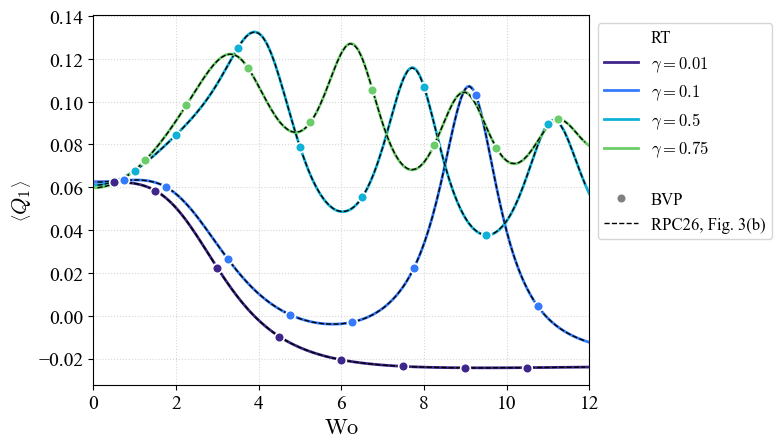

theta = 0.0028, vartheta = 0.0051


In [11]:
fig, ax = plt.subplots()
ax.set_xlabel(r'$\mathrm{Wo}$')
ax.set_ylabel(r'$\left\langle Q_1 \right\rangle$')
ax.set_xlim(0, 12)
ax.grid(alpha=0.5, linestyle='dotted')

for my_gamma, my_color in zip(gamma_vals, colors):
  ax.plot(Wo_RT, Q1_RT[my_gamma], lw=2, color=my_color, label=rf'$\gamma = {my_gamma}$')
  ax.plot(RPC26_fig3b[my_gamma]['Wo'], RPC26_fig3b[my_gamma]['Q1'], lw=1, ls='dashed', color='black')
  ax.plot(Wo_BVP[my_gamma], Q1_BVP[my_gamma], 'o', ms=7, mec='white', mew=1.2, color=my_color, zorder=3)

# legend: 'RT' as a heading over the gamma curves, then a blank row
handles, labels = ax.get_legend_handles_labels()
blank = Line2D([], [], ls='', marker='')
handles = [blank] + handles + [blank,
           Line2D([], [], marker='o', ms=7, mec='white', mew=1.2, ls='', color='gray'),
           Line2D([], [], lw=1, ls='dashed', color='black')]
labels = ['RT'] + labels + ['', 'BVP', 'RPC26, Fig. 3(b)']
ax.legend(handles, labels, bbox_to_anchor=(1, 1))

plt.show()

print(f'theta = {theta_ref}, vartheta = {vartheta_ref}')

The RT agrees with the BVP to about $10^{-5}$ (relative) and with Fig. 3(b) of [RPC26] to about $10^{-4}$, the accuracy of the digitization. For the larger values of $\gamma$, $\langle Q_1 \rangle$ shows the resonance-like peaks discussed by [RPC26].

## Flow-rate control

Under flow-rate control, the primary pressure is the pressure-control profile multiplied by a constant,
$$
  \frac{\sinh\big(\kappa(1-Z)\big)}{\mathfrak{f}_0 \kappa \cosh \kappa} = C\,\frac{\sinh\big(\kappa(1-Z)\big)}{\sinh \kappa},
  \qquad C := \frac{\tanh\kappa}{\mathfrak{f}_0\kappa},
$$
with the same $\kappa$, where $C = P_{0,a}(0)$ is the amplitude of the primary pressure drop needed to drive a unit flow rate. The slip velocity and the advective forcing are quadratic in the primary flow, so $I_1$ and $I_2$ are $|C|^2$ times their values under pressure control. With $\langle Q_1 \rangle = 0$, the RT then gives the rectified pressure drop
$$
  \langle \Delta P_1 \rangle = -12\,(I_1 + I_2) = -12\,|C|^2 \langle Q_1 \rangle_\mathrm{p},
$$
where $\langle Q_1 \rangle_\mathrm{p}$ is the rectified flow rate under pressure control, computed above. So the plot of $\langle Q_1 \rangle_\mathrm{p}$ above, rescaled, is also the flow-rate-control result. As $\mathrm{Wo},\gamma\to0$, $C \to 1/\mathfrak{f}_0 \to 12$ and $\langle Q_1 \rangle_\mathrm{p} \to 1/16$, so $\langle \Delta P_1 \rangle \to -108$.

Below, we check this by computing $\langle \Delta P_1 \rangle$ directly, with the flow-rate-controlled primary flow, by both the RT and the BVP.

In [12]:
def C_flow(Wo, gamma, theta, vartheta):
  # amplitude of the primary pressure drop under flow-rate control, P_{0,a}(0)
  kappa, f0, fw = coefficients(Wo, gamma, theta, vartheta)
  return np.tanh(kappa)/(f0*kappa)

# direct computation at the reference parameters, by the RT and by the BVP
I1, I2 = I1_I2_RT(slip_flow, forcing_flow, Wo_ref, gamma_ref, theta_ref, vartheta_ref)
I2_bvp = I2_BVP(forcing_flow, Wo_ref, gamma_ref, theta_ref, vartheta_ref)
dP1 = -12*(I1 + I2)
dP1_bvp = -12*(I1 + I2_bvp)
Q1_p = sum(I1_I2_RT(slip_pressure, forcing_pressure, Wo_ref, gamma_ref, theta_ref, vartheta_ref))
print(f'<dP1> = {dP1:.6f} (RT), {dP1_bvp:.6f} (BVP), {-12*abs(C_flow(Wo_ref, gamma_ref, theta_ref, vartheta_ref))**2*Q1_p:.6f} (-12|C|^2 <Q1>_p)')

# small-Wo, small-gamma limit
for my_gamma in [1e-3, 1e-2]:
  my_dP1 = -12*sum(I1_I2_RT(slip_flow, forcing_flow, 0.01, my_gamma, theta_ref, vartheta_ref))
  print(f'gamma = {my_gamma:g}, Wo = 0.01: <dP1> = {my_dP1:.3f} (limit -108)')

<dP1> = -17.941181 (RT), -17.941196 (BVP), -17.941181 (-12|C|^2 <Q1>_p)
gamma = 0.001, Wo = 0.01: <dP1> = -107.998 (limit -108)
gamma = 0.01, Wo = 0.01: <dP1> = -107.752 (limit -108)


In [13]:
# check <dP1> = -12 |C|^2 <Q1>_p over the Wo range of the plot above, for each gamma
for my_gamma in gamma_vals:
  my_Wo = Wo_RT[::8]
  dP1_direct = np.array([-12*sum(I1_I2_RT(slip_flow, forcing_flow, w, my_gamma, theta_ref, vartheta_ref))
                         for w in my_Wo])
  dP1_rescaled = -12*np.abs(C_flow(my_Wo, my_gamma, theta_ref, vartheta_ref))**2*Q1_RT[my_gamma][::8]
  my_err = np.max(np.abs(dP1_direct - dP1_rescaled)/np.abs(dP1_rescaled).max())
  print(f'gamma = {my_gamma}: max relative difference = {my_err:.1e} ({my_Wo.size} values of Wo)')

gamma = 0.01: max relative difference = 2.6e-16 (30 values of Wo)


gamma = 0.1: max relative difference = 8.5e-16 (30 values of Wo)


gamma = 0.5: max relative difference = 7.1e-16 (30 values of Wo)


gamma = 0.75: max relative difference = 4.9e-16 (30 values of Wo)


Only the integrated quantities are related by a pure rescaling. The streaming-pressure profiles differ by a linear term: the flux source $\tfrac{1}{2}V_\mathrm{slip} + \int_0^1 \widetilde{\langle V_{Z,1}\rangle}\,dY$ at each $Z$ also scales by $|C|^2$, but the end conditions differ, giving
$$
  \langle P_1\rangle_\mathrm{f}(Z) = |C|^2\left[\langle P_1\rangle_\mathrm{p}(Z) - 12\langle Q_1\rangle_\mathrm{p}(1-Z)\right],
$$
where the subscript $\mathrm{f}$ denotes flow-rate control. That is, the flow-rate-control profile is the rescaled pressure-control profile plus the Poiseuille pressure that cancels its net flux. The mixed conditions of the experiments of [HPFC25], in which the primary flow is driven by the inlet pressure, $P_{0,a}(0) = 1$, but no net mean flow is allowed, $\langle Q_1 \rangle = 0$, give the same profile on the pressure-control scale, $\langle P_1\rangle_\mathrm{f}/|C|^2$: the primary condition sets only the scale, $|C|^2$, while the mean condition sets the shape.

# Summary

- The RT gives the rectified flow rate (under pressure control) or pressure drop (under flow-rate control) of [RPC26] as a single quadrature, without solving a BVP at each $Z$, which makes sweeps over $\mathrm{Wo}$ cheap.
- It agrees with the direct BVP solution, with the small-$\mathrm{Wo}$ limit of [RPC26], and with Fig. 3(b) of [RPC26].
- Under flow-rate control, the primary pressure is the pressure-control profile multiplied by $C = \tanh\kappa/(\mathfrak{f}_0\kappa)$, so the rectified pressure drop is $\langle \Delta P_1 \rangle = -12|C|^2\langle Q_1 \rangle_\mathrm{p}$ and needs no new computation.

# References

*   [CV20] T. G. J. Chandler, D. Vella, Validity of Winkler's mattress model for thin elastomeric layers: beyond Poisson's ratio, _Proc. R. Soc. A_ **476** (2020) 20200551. [doi:10.1098/rspa.2020.0551](https://doi.org/10.1098/rspa.2020.0551); [arXiv:2010.11133](https://arxiv.org/abs/2010.11133)

*   [HPFC25] A. Huang, S. D. Pande, J. Feng, I. C. Christov, Oscillatory flows in three-dimensional deformable microchannels, _J. Fluid Mech._ **1022** (2025) A38. [doi:10.1017/jfm.2025.10771](https://doi.org/10.1017/jfm.2025.10771); [arXiv:2504.05132](https://arxiv.org/abs/2504.05132)

*   [PBC26] S. D. Pande, E. Boyko, I. C. Christov, Reciprocal theorem for calculating the flow rate of oscillatory channel flows, _Mech. Res. Commun._ **151** (2026) 104589. [doi:10.1016/j.mechrescom.2025.104589](https://doi.org/10.1016/j.mechrescom.2025.104589); [arXiv:2312.10183](https://arxiv.org/abs/2312.10183)

*   [PWC23] S. D. Pande, X. Wang, I. C. Christov, Oscillatory flows in compliant conduits at arbitrary Womersley number, _Phys. Rev. Fluids_ **8** (2023) 124102. [doi:10.1103/PhysRevFluids.8.124102](https://doi.org/10.1103/PhysRevFluids.8.124102); [arXiv:2304.00543](https://arxiv.org/abs/2304.00543)

*   [RPC26] U. M. Rade, S. D. Pande, I. C. Christov, Theory and simulation of elastoinertial rectification of oscillatory flows in two-dimensional deformable rectangular channels, _Phys. Rev. Fluids_ **11** (2026) 074102. [doi:10.1103/zk9v-13sn](https://doi.org/10.1103/zk9v-13sn); [arXiv:2505.22799](https://arxiv.org/abs/2505.22799)

*   [ZR24] X. Zhang, B. Rallabandi, Elasto-inertial rectification of oscillatory flow in an elastic tube, _J. Fluid Mech._ **996** (2024) A16. [doi:10.1017/jfm.2024.612](https://doi.org/10.1017/jfm.2024.612); [arXiv:2404.02292](https://arxiv.org/abs/2404.02292)